# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 9</span>


### The Traveling Salesman Problem

The traveling salesman problem (TSP) consists of a salesman and a set of $N$ cities with positions $\vec{c}_i$. The salesman **has to visit each one of the cities starting from a certain one (e.g. the hometown) and returning to the same city**. The challenge of the problem is that the traveling salesman wants to **minimize the total length of the trip**.

Consider now the ordered sequence of cities, $\vec{c}_1, \vec{c}_2, \dots, \vec{c}_N$, which goes from city 1 to the n$^{th}$ city. The path that minimizes the following loss/cost function:

$$
L^{(2)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N) = \sum_{i=1}^{N} |\vec{x}_i-\vec{x}_{i+1}|^2
$$

or 
$$
L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N) = \sum_{i=1}^{N} |\vec{x}_i-\vec{x}_{i+1}|
$$


(with $\vec{x}_{N+1}=\vec{x}_1$) is one particular permutation, P, of the ordered sequence of cities $\vec{c}_1, \vec{c}_2, \dots, \vec{c}_N$, i.e. 

$$
\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N = \vec{c}_{P1}, \vec{c}_{P2}, \dots, \vec{c}_{PN}
$$

Note also that any particular permutation of the ordered sequence of cities can be obtained from the combination of many simple permutations among pairs of cities.

We can express a possible path via a 1D vector whose elements, from the first to the last, are integers that represents the cities in the order in which the salesman would visit them; for example for $N=5$ cities one possible path is represented by the vector:

$$
\left[ 1, 3, 5, 4, 2 \right]
$$

**Alteratively**, we can express a possible path also via a configuration of a $N\times N$ 2D *Ising-like* model with the following bonds:
1. any row must have one and at most one up spin
2. any column must have one and at most one up spin,

all the other spins are down.

We can represent such a configuration with a $N\times N$ matrix whose elements are 1 (spin up) or 0 (spin down); for example, in the case of a TSP with 5 cities:
$$
\begin{bmatrix}
1 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 1\\
0 & 1 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & 0\\
0 & 0 & 1 & 0 & 0\\
\end{bmatrix}
$$

You can interpret this matrix in the following way:
- column index represents time of visit: first colum = first visit, etc.
- row index represents the ordered sequence of cities: first row = first city, etc.

the previous matrix thus refers to the following sequence:

$$
\vec{x}_1, \vec{x}_2, \vec{x}_3, \vec{x}_4, \vec{x}_5 = 
\vec{c}_{1}, \vec{c}_{3}, \vec{c}_{5}, \vec{c}_{4}, \vec{c}_{2}
$$

and thus to the following *cost* of the path:

$$
L^{(2)}(\vec{x}_1, \dots, \vec{x}_5) = 
|\vec{c}_1-\vec{c}_3|^2 + |\vec{c}_3-\vec{c}_5|^2 + |\vec{c}_5-\vec{c}_4|^2 +
|\vec{c}_4-\vec{c}_2|^2 + |\vec{c}_2-\vec{c}_1|^2
$$

or
$$
L^{(1)}(\vec{x}_1, \dots, \vec{x}_5) = 
|\vec{c}_1-\vec{c}_3| + |\vec{c}_3-\vec{c}_5| + |\vec{c}_5-\vec{c}_4| +
|\vec{c}_4-\vec{c}_2| + |\vec{c}_2-\vec{c}_1|
$$


Note that, for this *ising-like* representation any particular permutation of the ordered sequence of cities can be obtained by a sequence of multiple pair permutations among rows and/or among columns.

**<span style="color:red">Warm suggestion: by using the 1D representation</span>** (but you can work with the representation you prefer or the one you are able to invent) ...

### Exercise 09.1

Write a code to solve the TSP with a **Genetic** algorithm (GA). Note that you should invent **some** *genetic-mutation* operators and a *genetic-crossover* operator which should preserve the bonds of the problem: the salesman must visit one and only one time every city and must be back to the first city in the end of the path.

Once the data structure of your code is ready, before you start coding your genetic operators, I warmly suggest you to code the creation of the starting population and to code a **check function** that verifies if every *individual* fulfils the bonds. Then check your starting population ... and use your check function every time you create a new individual.

You have to invent also a **selection** operator. 
The fitness and thus the order of the population should be obtained from $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$. Once your starting population has been ordered on a fitness basis,
you have 2 possibilities:
1. write a selection operator which obtain the probability to select an individual from $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$
2. write a selection operator which simply uses the order in the orderd population with $M$ individuals, e.g. select the individual $j$ with the algorithm: $j= int(M \times r^p)+1$ where $r$ is a uniform random number $r\in[0,1)$ and $p$ a convenient exponent. 

<span style="color:red">Set the first city to always appear at position 1, so as to reduce the degeneration of the shortest route to be 2, which corresponds to walking the shortest route in clockwise and anti-clockwise directions.</span>

Then you can start introducing some *genetic-mutation* operators, for example:
1. pair permutation of cities (except for the first city), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 2, 4, 3, 5 \right]$ (At this point you should already have such operator ... how have you generated the starting population?).
2. shift of $+n$ positions for $m$ contiguous cities (except for the first city and $m \lt N-1$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a $+2$ shift of the second and third cities.
3. permutation among $m$ contiguous cities (except for the first city) with other (different!) $m$ contiguous cities ($m<N/2$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a permutation of the second and third cities with the last 2.
4. inversion of the order in which they appear in the path of $m$ cities (except for the first city and $m \le N$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 3, 2, 5 \right]$ for the inversion of the cities from 2 to 4.

Every mutation will have its probability, $p^{(i)}_m$ to be called and typically $p^{(i)}_m < 10\%$, but before to include crossover you can check if the GA is able to perform a good *random search* using only mutation operators (in this case $p^{(i)}$ could be higher than in the previous suggestion).

At this point you can add a *crossover* operator (that fulfils the bonds and that you will call with probability $p^{(i)}_c > 50\%$):

given a selected mother and father, e.g. 
$$
\left[ 1, 2, 3, 4, 5 \right]\\
\left[ 1, 5, 4, 3, 2 \right] 
$$
1. cut their paths at the same position:
$$
\left[ 1, 2, 3 | 4, 5 \right]\\
\left[ 1, 5, 4 | 3, 2 \right] 
$$
2. conserve the first part of the paths:
$$
\left[ 1, 2, 3 | X, Y \right]\\
\left[ 1, 5, 4 | X, Y \right] 
$$
3. complete the paths with the missing cities adding them in the **order** in which they appear in the consort:
$$
\left[ 1, 2, 3 | 5, 4 \right]\\
\left[ 1, 5, 4 | 2, 3 \right] 
$$

Here you are: you have two sons that you can add to the new generation ... and so on!

Apply your code to the optimization of a path among 

- <span style="color:blue">34 cities randomly placed **on** a circumference</span>
- <span style="color:blue">34 cities randomly placed **inside** a square</span>

Show your results via:

- a picture of $L^{(1)}$ of the best path and of $\langle L^{(1)}\rangle$, averaged on the best half of the population, as a function of the iterations/generations of your algorithm</span>
- a picture of the best path in cartesian coordinates</span>

# <span style="color:green"> RESULTS: </span>

In this notebook we will solve the traveling salesman problem (TSP) with a genetic algorithm (GA) on two sets of $N=34$ cities; the first randomly placed on a circumference, the second randomly placed inside a unit square.

### Genetic algorithm
A GA mimics biological evolution: a population of candidate solutions (in our case, trips) evolves over many generations, and the fittest individuals (for us the shortest trips) are the ones that reproduce. Each new generation is built in three steps:
1. Selection of two parents from the population;
2. Crossover, where, with a probability of $p_c=80\%$, the parents exchange information to produce two offspring (otherwise the offspring are copies of the parents);
3. Mutation of the offspring, which introduces variability that crossover alone cannot create.

We also used elitism: the best trip of each generation is copied unchanged into the next one, whether or not it is selected as a parent, so the best $L^{(1)}$ never increases. In our simulations the population had $M=300$ individuals and evolved for 200 generations (circle) or 500 generations (square).

#### Trip representation:
We created a class <small><code>trip</code></small> whose members are the number of cities and a vector of <small><code>city</code></small>, a struct with the city id and its coordinates:
<small>

```cpp
struct city{
    int id;
    double x, y;
    city() : id(0), x(0.), y(0.) {}
    city(int id, double x, double y) : id(id), x(x), y(y) {}
};
```
</small>

The path is represented by the vector of cities in the order of visit. The first city is the same for every trip and is never touched by mutations or crossover, so the shortest path is only two-fold degenerate: clockwise and anti-clockwise. After every crossover (and after every mutation in debug mode) the function <small><code>check()</code></small> verifies that no city is visited more than once:
<small>

```cpp
void trip :: check() {
    std::map<int, bool> visited;
    for (int i = 0; i < _n_cities; i++) {
        if (visited.find(cities[i].id) != visited.end()) std::exit(EXIT_FAILURE);
        visited[cities[i].id] = true;
    }
};
```
</small>

#### Mutations:
The class <small><code>trip</code></small> also implements the mutations, which are applied to the offspring after the crossover. All of them act on the indices $\ge1$, so the first city is never moved. Only the essential lines are shown; <small><code>block_length</code></small> is the number $m$ of cities involved.

1. Swap of two different cities:
<small>

```cpp
int first_index = int(rnd.Rannyu(1, _n_cities));
int second_index = int(rnd.Rannyu(1, _n_cities));
while (first_index == second_index) second_index = int(rnd.Rannyu(1, _n_cities));
swap(cities[first_index], cities[second_index]);
```
</small>

2. Shift of $m$ contiguous cities by $n$ positions: the block is removed from the path and reinserted $n$ positions further (cyclically, among the remaining cities):
<small>

```cpp
int start_indx = int(rnd.Rannyu(1, _n_cities - block_length + 1));       // the block never exceeds the path
vector<city> temp(cities.begin() + 1, cities.end());                      // path without the first city
vector<city> block(temp.begin() + (start_indx - 1), temp.begin() + (start_indx - 1 + block_length));
temp.erase(temp.begin() + (start_indx - 1), temp.begin() + (start_indx - 1 + block_length));
int insert_pos = (start_indx - 1 + n_shift) % (_n_cities - block_length);
temp.insert(temp.begin() + insert_pos, block.begin(), block.end());
for (int i = 1; i < _n_cities; ++i) cities[i] = temp[i - 1];
```
</small>

3. Permutation of two different, non-overlapping blocks of $m$ cities:
<small>

```cpp
int start_indx_1 = int(rnd.Rannyu(1, _n_cities - 2 * block_length + 1));
int end_1        = start_indx_1 + block_length;
int start_indx_2 = int(rnd.Rannyu(end_1, _n_cities - block_length + 1));  // second block starts after the first
std::swap_ranges(cities.begin() + start_indx_1, cities.begin() + end_1, cities.begin() + start_indx_2);
```
</small>

4. Inversion of the order of $m$ contiguous cities:
<small>

```cpp
int start_indx = int(rnd.Rannyu(1, _n_cities - block_length + 1));
std::reverse(cities.begin() + start_indx, cities.begin() + start_indx + block_length);
```
</small>

Each of the four mutations is applied to each offspring with probability $p_m=10\%$, independently of the others, so on average $0.4$ mutations are performed per offspring. The lengths of the blocks are drawn as $m=m_{\min}+\lfloor(m_{\max}-m_{\min}+1)\,r^2\rfloor$ with $r\in[0,1)$ uniform; short blocks are favoured, but long ones remain possible, which helps to avoid stalling in local minima. This is needed especially for the inversion, because with the first city fixed removing a crossing of the path can require inverting almost the whole path.

#### Selection algorithms:
Once the class <small><code>trip</code></small> was ready, we implemented the class <small><code>GA</code></small>, which contains the methods of the genetic algorithm, such as the selection rules and the crossover. We implemented two selection algorithms based on two different principles. The first one selects an individual with a probability proportional to the fitness $1/L^{(1)}$ (roulette-wheel selection: the shorter the path, the larger its share of the wheel):
<small>
```cpp
double p = rnd.Rannyu(0., sum_inv_loss);          // sum_inv_loss = sum of 1/L over the population
double acc = 0.;
for (auto it = population.begin(); it != population.end(); it++) {
    acc += 1. / it->first;
    if (acc >= p) return it->second;
}
```
</small>

However, its selection pressure is always weak: the ratio between the probabilities of the best and of the worst individual is just $L_{\rm worst}/L_{\rm best}$, which is only about $1.5$ even in a random population and tends to $1$ as the population converges, so the selection is almost uniform. The second algorithm uses only the ranking of the population, which is kept ordered by $L^{(1)}$, and selects the individual $j=\mathrm{int}(M\,r^p)$, with $r\in[0,1)$ uniform and $j=0$ the best one:
<small>

```cpp
double r = rnd.Rannyu();
int j = static_cast<int>(M * std::pow(r, p));
auto it = population.begin();
std::advance(it, j);
return it->second;
```
</small>

This is the one used in the simulations, with $p=2$. Since the population is ordered by increasing $L^{(1)}$, $j=0$ is the best individual, and raising $r\in[0,1)$ to a power $p>1$ pushes it towards $0$ (for $p=2$, $r=0.5$ becomes $0.25$), so low indices, i.e. short paths, are drawn more often. For large $M$ the probability of selecting an individual among the best fraction $x$ of the population is:
$$
P\!\left(\frac{j}{M}\le x\right)=P\!\left(r\le x^{1/p}\right)=x^{1/p},
$$
which for $p=1$ is just $x$ (uniform selection), while for $p=2$ the best $10\%$ of the population is selected with probability $\sqrt{0.1}\simeq32\%$ and the best half with $\sqrt{0.5}\simeq71\%$. The probability of selecting the $j$-th individual is $\sqrt{(j+1)/M}-\sqrt{j/M}$, so the best individual is chosen about $2\sqrt M\simeq35$ times more often than the worst one, but every individual keeps a non-zero probability of being selected, which preserves diversity. The parameter $p$ tunes the selection pressure: the larger $p$, the more the best individuals are favoured. Moreover, this rule depends only on the order of the population and not on the values of $L^{(1)}$, so the selection pressure stays the same during the whole run.

#### Crossover
The two parents are cut at the same random position (between $1$ and $N-2$, so the first city is always kept). Each child keeps the first part of one parent and is completed with the missing cities in the order in which they appear in the other parent, so that every city is visited exactly once:
<small>

```cpp
int cut_indx = int(rnd.Rannyu(1, t1._n_cities - 1));
// in_child1[id] = true for the cities already copied from t1 (the first cut_indx ones)
for (int i = 0; i < _n_cities; i++) {
    int id = t2.cities[i].id;
    if (!in_child1[id]) { child1[indx1++] = t2.cities[i]; in_child1[id] = true; }
}
// the second child is built in the same way, exchanging the roles of t1 and t2
```
</small>

The following figures show, from left to right, the loss $L^{(1)}$ as a function of the GA generation (for the best path and averaged over the best half of the population), the evolution of the best path (animated in the gif), and finally the best path found by the simulation:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

In [2]:
SRC = "SOURCE"   # cities_config_*.dat
OUT = "OUTPUT"   # best_loss_*.dat, mean_loss_*.dat, best_trip_*.dat

def load_table(fname):
    """Legge un file numerico ignorando header e righe non numeriche."""
    rows = []
    with open(fname) as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            try:
                rows.append([float(x) for x in parts])
            except ValueError:
                continue
    return np.array(rows)

def load_trips(fname):
    """Ritorna generazioni, loss e percorsi da best_trip_*.dat."""
    gens, losses, paths = [], [], []
    with open(fname) as f:
        for line in f:
            parts = line.split()
            if len(parts) < 3:
                continue
            try:
                g, l = int(parts[0]), float(parts[1])
                p = [int(x) for x in parts[2:]]
            except ValueError:
                continue  # header
            gens.append(g); losses.append(l); paths.append(p)
    return np.array(gens), np.array(losses), paths

def path_xy(cities, path):
    """Coordinate (x, y) del percorso, ciclo chiuso, gestisce indici 0/1-based."""
    p = np.array(path)
    if p.min() == 1:
        p = p - 1
    xy = cities[p]
    return np.vstack([xy, xy[0]])

In [ ]:
def analyze_and_gif(shape, n_frames=60, fps=8, hold=10):

    # Load city coordinates (last two columns = x, y), loss curves and best-trip history
    cities = load_table(f"{SRC}/cities_config_{shape}.dat")[:, -2:]
    best   = load_table(f"{OUT}/best_loss_{shape}.dat")
    mean   = load_table(f"{OUT}/mean_loss_{shape}.dat")
    gens, losses, paths = load_trips(f"{OUT}/best_trip_{shape}.dat")

    # Index of the best path found (minimum L^(1))
    i_best = int(np.argmin(losses))

    # Evenly spaced frames from the first generation up to the best path
    idx = np.unique(np.linspace(0, i_best, n_frames).astype(int))
    idx = np.concatenate([idx, [i_best] * hold])

    # Common axis limits for the two path panels
    pad = 0.1 * np.ptp(cities, axis=0).max()
    xlim = (cities[:, 0].min() - pad, cities[:, 0].max() + pad)
    ylim = (cities[:, 1].min() - pad, cities[:, 1].max() + pad)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

    #loss vs generation 
    ax1.plot(best[:, 0], best[:, 1], color = '#0c459a', label=r"$L^{(1)}$ best path")
    ax1.plot(mean[:, 0], mean[:, 1], color = '#109e28', label=r"$\langle L^{(1)}\rangle$ best half")
    vline = ax1.axvline(gens[idx[0]], color="gray", ls="--", lw=1)  # marks the current generation
    ax1.set_xlabel("Generation")
    ax1.set_ylabel(r"$L^{(1)}$")
    ax1.set_title(f"Loss vs generation - {shape}")
    ax1.grid(alpha=0.3)
    ax1.legend()

    #animated path 
    ax2.scatter(cities[:, 0], cities[:, 1], c="k", s=20, zorder=3)
    line, = ax2.plot([], [], "-", color='#0c459a', lw=1.3)  # empty line, updated at each frame
    ax2.set_xlim(*xlim); ax2.set_ylim(*ylim); ax2.set_aspect("equal")
    ax2.set_xlabel("x"); ax2.set_ylabel("y")
    title2 = ax2.set_title("")

    #best path
    xy_best = path_xy(cities, paths[i_best])
    ax3.plot(xy_best[:, 0], xy_best[:, 1], "-o", color = '#0c459a',  ms=5, lw=1.2)
    ax3.plot(*xy_best[0], "r*", ms=15, label="start")  # starting city
    ax3.set_xlim(*xlim); ax3.set_ylim(*ylim); ax3.set_aspect("equal")
    ax3.set_xlabel("x"); ax3.set_ylabel("y")
    ax3.set_title(f"Best path - {shape} (L = {losses[i_best]:.4f})")
    ax3.legend()

    fig.tight_layout()

    # Called by FuncAnimation at every frame k
    def update(k):
        i = idx[k]                                   # row of best_trip file shown in this frame
        xy = path_xy(cities, paths[i])               # path coordinates (closed loop)
        line.set_data(xy[:, 0], xy[:, 1])            # update the path in panel 2
        title2.set_text(f"generation {gens[i]} - L = {losses[i]:.4f}")
        vline.set_xdata([gens[i], gens[i]])          # move the vertical line in panel 1
        return line, title2, vline

    gif = f"{OUT}/best_path_{shape}.gif"
    png = f"{OUT}/best_path_{shape}.png"

    # Build and save the animation
    anim = FuncAnimation(fig, update, frames=len(idx), blit=False)
    anim.save(gif, writer=PillowWriter(fps=fps))

    update(len(idx) - 1)                       # last frame = best path
    fig.savefig(png, dpi=150, bbox_inches="tight")  # static PNG, useful for PDF/HTML export
    plt.close(fig)                             # close the figure without displaying it
    display(Image(filename=gif))               # show only the animated GIF

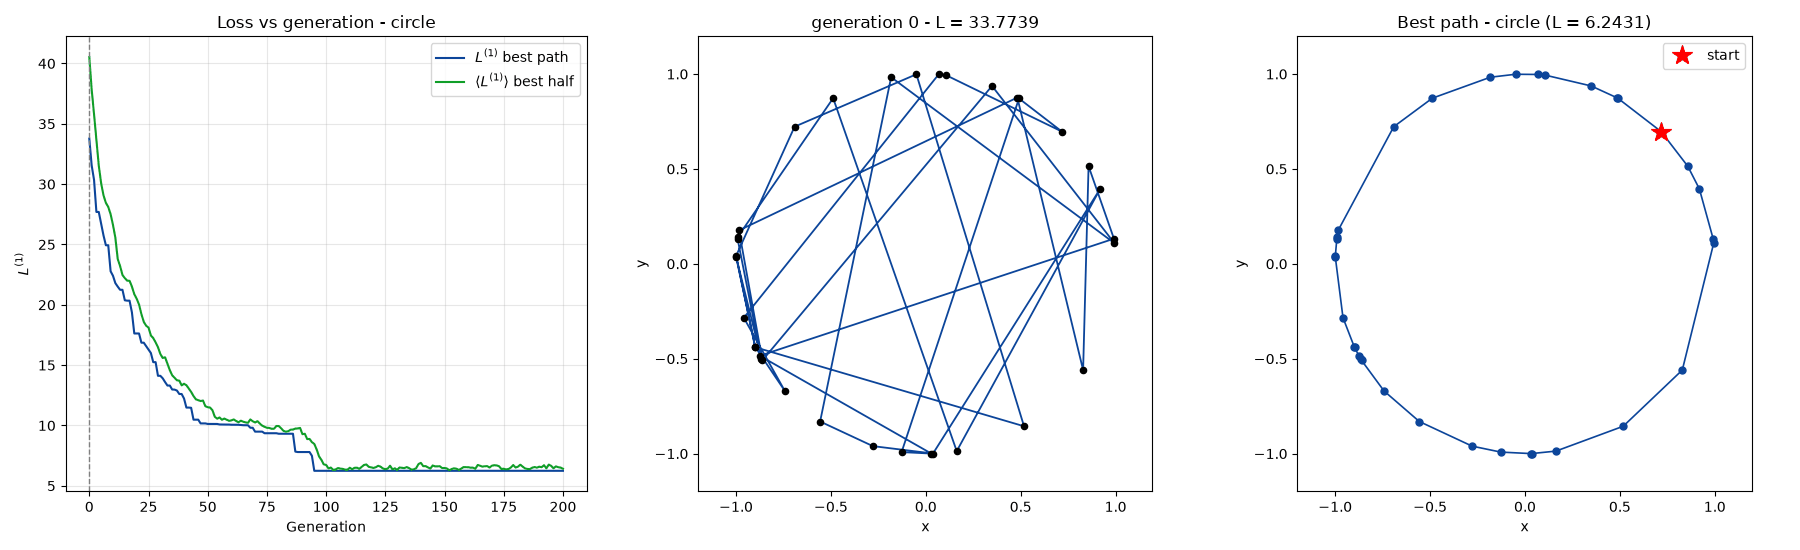

In [4]:
analyze_and_gif("circle")

For the cities randomly placed on a circumference the best path is the polygon that visits the cities in angular order. This is the exact solution of this case ($L^{(1)}_{\min}=6.2431$) since the shortest path cannot cross itself and for points on a circumference the only path without crossings is the convex polygon. The GA reaches it after about $100$ generations and then keeps it thanks to the elitism criterion. From the animated image of the paths we can see that the best $L^{(1)}$ decreases by steps, and each long plateau ends when a mutation removes a long crossing of the path. Another thing that can be noticed is that in the loss plot the average over the best half of the population stays slightly above the best value, that is because each generation is made almost entirely of new offspring, about $34\%$ of which are mutated, and most mutations of a good path make it worse.

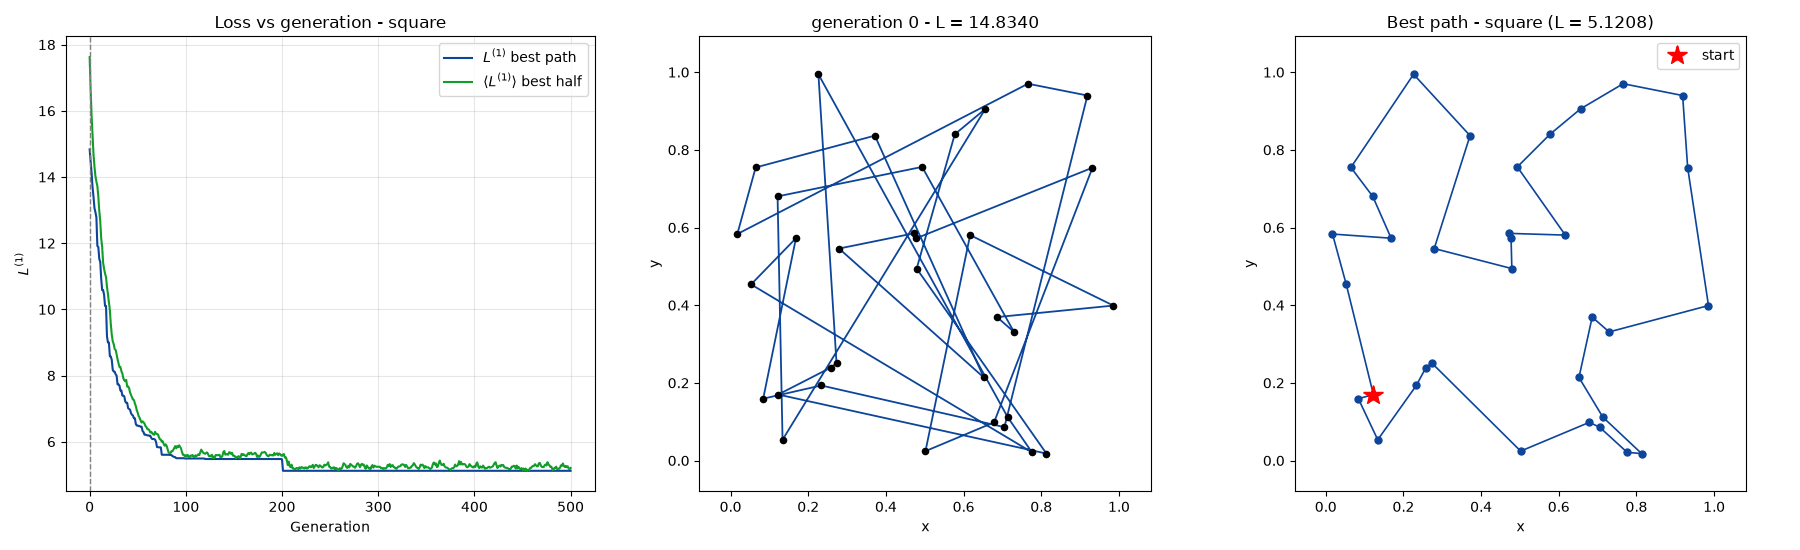

In [5]:
analyze_and_gif("square")

For the cities randomly placed inside a unit square the best path has $L^{(1)}=5.1208$ and shows no crossing, which is a necessary but not sufficient condition for a path to be the shortest one. With $33!/2\approx4\cdot10^{36}$ possible paths an exhaustive search would take a very long time, so we cannot prove that this is the exact minimum. The curve shows a plateau at $L^{(1)}\approx5.5$ between generations $\approx100$ and $\approx200$, which ends with a sudden drop to the final value, probably when the crossing visible at generation $146$ is removed. After generation $200$ no further improvement is found but we still cannot say we found the best path.